In [2]:
import numpy as np
from matplotlib import pyplot as plt
import enlighten
import shapely

from scipy.interpolate import interp1d

from utils import Modulator_CPS


from imodulator.ChargeSimulator import ChargeSimulatorSolcore
from imodulator.OpticalSimulator import OpticalSimulatorFEMWELL, OpticalSimulatorMODE
from imodulator.ElectroOpticalSimulator import ElectroOpticalSimulator
from imodulator.RFSimulator import RFSimulatorFEMWELL as RFSimulator

from utils_data_analysis import get_EO
import skrf as rf

from utils_fom import get_fom

import os
import json

%matplotlib widget

Failed to import lumapi: [Errno 2] No such file or directory: 'C:/Program Files/Lumerical/v232/api/python/lumapi.py'


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\solcore\registries.py:73: UserWarning: Optics solver 'RCWA' will not be available. An installation of S4 has not been found.
  warn(
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\nextnanopy\defaults.py:202: UserWarning: Unsupported products in config file: ['nextnano.NEGF++'] will be ignored. To not see this message, please remove unsupported products from the config file: C:\Users\20230622\.nextnanopy-configNote: nextnano.NEGF++ was renamed to nextnano.NEGF, nextnano.NEGF was renamed to nextnano.NEGF_classic. Please check the documentation for more details.
  warnings.warn(


Successfully imported nextnanopy
Successfully configured nextnano++ settings
  [OK] nextnano++ exe: C:/Program Files/nextnano/2026_07_03/nextnano++/bin/nextnano++_Intel_64bit.exe
  [OK] nextnano++ license: C:/Users/20230622/OneDrive - TU Eindhoven/PhD/License_nnp.lic
  [OK] nextnano++ database: C:/Program Files/nextnano/2026_07_03/nextnano++/database/database.nnp
  [OK] nextnano++ outputdirectory: D:/Repos/imodulator/tests\nn_output
nextnano configuration test passed: all paths are valid.


In [3]:
modulator = Modulator_CPS(dop_L4 = -1e18, dop_L3 = 1e18)
data_to_return, rf_sim, mode, charge = get_fom(modulator, verbose=True)

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in sqrt
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: overflow encountered in exp
  result_magnitude = func(*stripped_args, **stripped_kwargs)


Calculating TE mode...
The polygon "background" is fully covered by a higher priority polygons. It will be removed from the simulation.
Meshing...
Total mesh elements: 15192
Computing modes...
Computing modes at wavelength 1.54 um...
Fundamental TE mode selected: 1
Computing modes at wavelength 1.55 um...
Fundamental TE mode selected: 1
Computing modes at wavelength 1.56 um...
Fundamental TE mode selected: 1
Effective index - mode 0: 3.2011
loss - mode 0: 32.69 dB/cm
power:  (1+0j)
TE fraction:  0.00028966087748921623
TM fraction:  0.9997103391225108
transversality: 0.976554977899733
#------------------------------------------#
Effective index - mode 1: 3.2004
loss - mode 1: 23.97 dB/cm
power:  (1.0000000000000004+0j)
TE fraction:  0.9996352537308676
TM fraction:  0.00036474626913240993
transversality: 0.9755124844748647
#------------------------------------------#
Effective index - mode 2: 3.1599
loss - mode 2: 0.31 dB/cm
power:  (0.9999999999999999+0j)
TE fraction:  0.000456530638671

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\solcore\sesame_drift_diffusion\solve_pdd.py:193: UserWarning: All voltages are positive, but junction has been identified as n-p, so the  open-circuit voltage (Voc) of the junction will be negative.
  warnings.warn(


Solving IV of the tunnel junctions...
Solving IV of the total solar cell...
Transfer PDD results to device...
Calculating electro-optic response...
The polygon "background" is fully covered by a higher priority polygons. It will be removed from the simulation.
Creating delta epsilon


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in sqrt
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: divide by zero encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: overflow encountered in exp
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facet

Calculating RF response...
meshing for RF simulation...
mode for refinement: 0, neff: 3.459386, loss: 206.94 dB/cm, nelements: 1324 | Z0: 45.84 Ohm
mode for refinement: 0, neff: 3.465716, loss: 206.70 dB/cm, nelements: 1584 | Z0: 42.50 Ohm
mode for refinement: 0, neff: 3.473535, loss: 206.87 dB/cm, nelements: 1722 | Z0: 41.48 Ohm
mode for refinement: 0, neff: 3.476920, loss: 206.97 dB/cm, nelements: 2229 | Z0: 40.02 Ohm
mode for refinement: 0, neff: 3.462896, loss: 193.67 dB/cm, nelements: 2489 | Z0: 40.21 Ohm
mode for refinement: 0, neff: 3.528303, loss: 210.85 dB/cm, nelements: 3331 | Z0: 38.43 Ohm
mode for refinement: 0, neff: 3.538315, loss: 211.70 dB/cm, nelements: 4070 | Z0: 37.02 Ohm
mode for refinement: 0, neff: 3.547525, loss: 211.92 dB/cm, nelements: 4660 | Z0: 35.49 Ohm
mode for refinement: 0, neff: 3.545733, loss: 209.93 dB/cm, nelements: 4698 | Z0: 35.34 Ohm
mode for refinement: 0, neff: 3.545839, loss: 210.01 dB/cm, nelements: 5364 | Z0: 35.33 Ohm
mode for refinement: 0, 

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\traitlets\traitlets.py:1385: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(


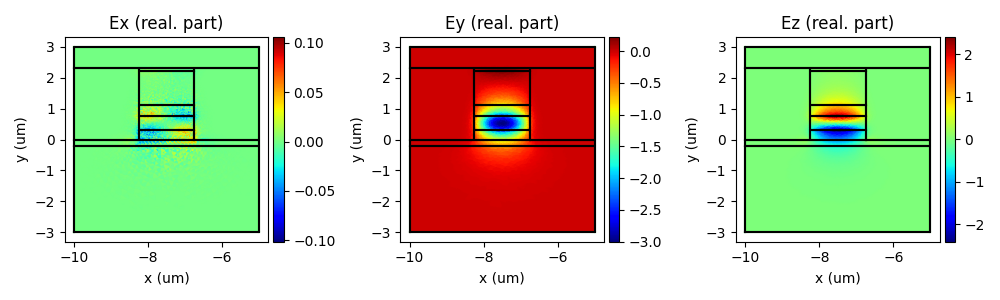

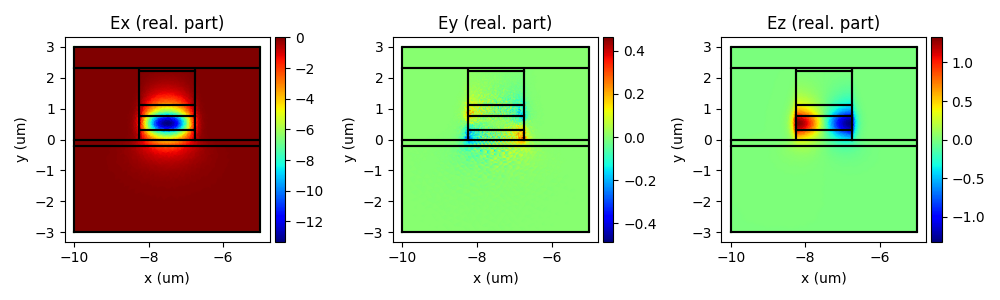

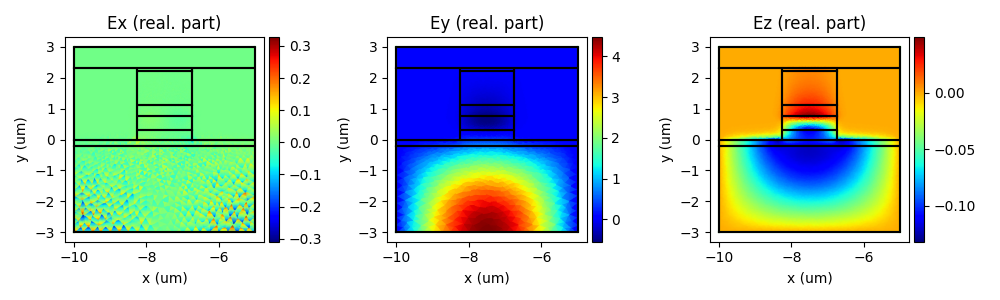

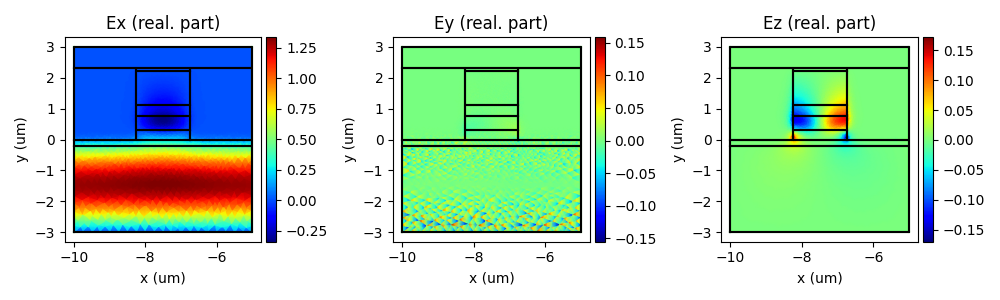

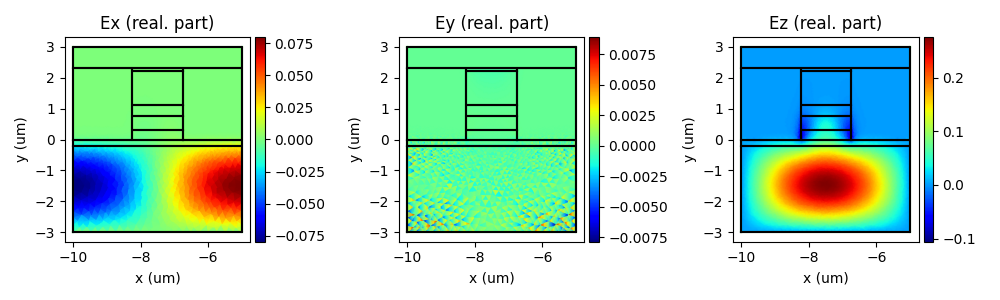

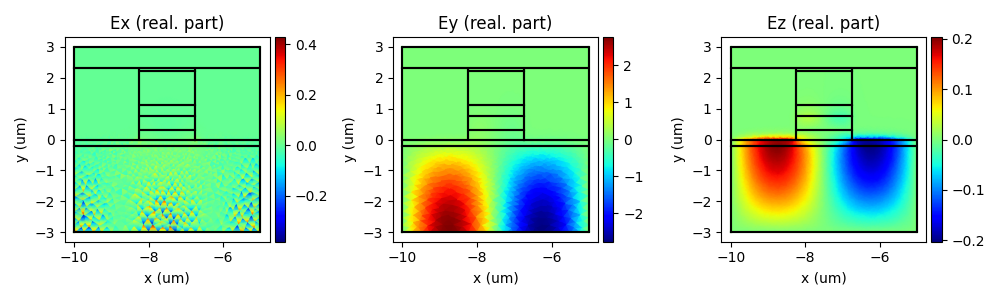

In [4]:
# modulator = Modulator_CPS(y_L3 = 0.45, dop_L3 = 1e15)
# sim_window = shapely.box(-10, -3, -5,3)

# mode = OpticalSimulatorFEMWELL(
#     device=modulator.device,
#     simulation_window=sim_window,
#     include_metals=True
# )
# mode.make_mesh()
# mode.plot_epsilon_optical()
# print(f"Mesh size: {mode.mesh.nelements} elements")
# m = mode.compute_modes(
#             wavelength=1.56,
#             num_modes=6,
#             order=1,
#             metallic_boundaries=True*0,
#             n_guess=3.2,
#             return_modes=True
#         )
# modes=m
# for i in range(len(modes)):
#     print(f'Effective index - mode {i}: {modes[i].n_eff.real:.4f}')
#     print(f'loss - mode {i}: {modes[i].calculate_propagation_loss(1e4):.2f} dB/cm')
#     print(f"power: ", modes[i].calculate_power())
#     print(f"TE fraction: ", modes[i].te_fraction)
#     print(f"TM fraction: ", modes[i].tm_fraction)
#     print(f"transversality: {modes[i].transversality}")
#     print('#------------------------------------------#')

for m in mode.modes:
	print()
	mode.plot_mode(m)

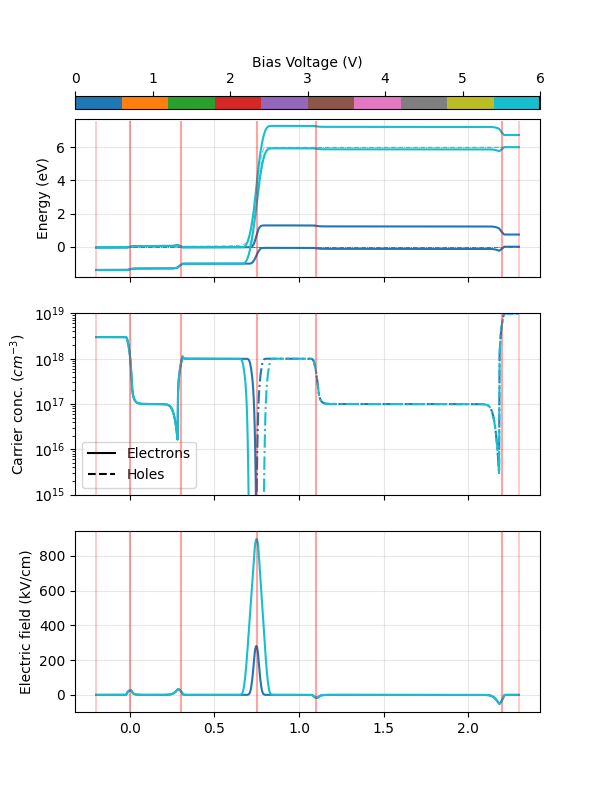

In [5]:
charge.plot_results()

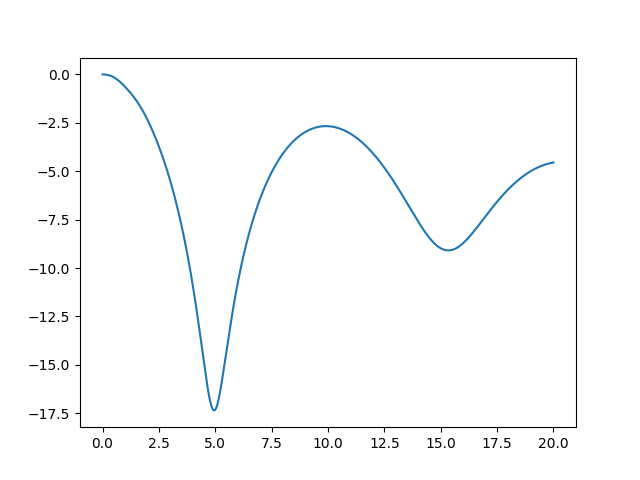

In [6]:
# print(data_to_return['phi_V'])
MZM_output = 1/2 * (1 + np.exp(1j*data_to_return['phi_V']/5))
MZM_Iout = np.abs(MZM_output)**2

# plt.figure()
# for i in range(5):
#     plt.plot(np.linspace(0,20,100_000),8.66*data_to_return['dalpha_V'][:,i])

plt.figure()
plt.plot(np.linspace(0,20,100_000), 10*np.log10(MZM_Iout))

In [ ]:
# from utils_fom import get_fom, select_fundamental_TE_mode
# select_fundamental_TE_mode(mode.modes, mode, modulator)

In [7]:
print(f'ng = {data_to_return["ng"]:.2f}')
print(f'VpiL = {data_to_return["VpiL"]:.2f} Vmm')
print(f'alpha = {data_to_return["loss_opt"]:.2f} dB/cm')
print(f'EE BW = {data_to_return["3dB_ee_bandwidth"]:.2f} GHz')
print(f'EO BW = {data_to_return["3dB_eo_bandwidth"]:.2f} GHz')

ng = 3.61
VpiL = 2.14 Vmm
alpha = 23.97 dB/cm
EE BW = 1.00 GHz
EO BW = 1.00 GHz


In [1]:
# core_y_values = np.linspace(0.45,0.7,20)
# core_dopant = np.logspace(15,18,20)

# ng_all = np.zeros((len(core_y_values), len(core_dopant)))
# n_opt_all = np.zeros((len(core_y_values), len(core_dopant)))
# loss_opt_all = np.zeros((len(core_y_values), len(core_dopant)))
# VpiL_all = np.zeros((len(core_y_values), len(core_dopant)))
# ER_all = np.zeros((len(core_y_values), len(core_dopant)))
# BW_EE_all = np.zeros((len(core_y_values), len(core_dopant)))
# BW_EO_all = np.zeros((len(core_y_values), len(core_dopant)))
# neff_RF_all = np.zeros((len(core_y_values), len(core_dopant), 12))
# loss_RF_all = np.zeros((len(core_y_values), len(core_dopant), 12))
# Z0_RF_all = np.zeros((len(core_y_values), len(core_dopant), 12))

# # data = np.load("data_electronic_photonic.npy", allow_pickle=True).item()
# # print(data.keys())
# # ng_all = data.get('ng')
# # n_opt_all = data.get('n_opt')
# # loss_opt_all = data.get('loss_opt')
# # VpiL_all = data.get('VpiL')
# # ER_all = data.get('ER')
# # BW_EE_all = data.get('3dB_ee_bandwidth')
# # BW_EO_all = data.get('3dB_eo_bandwidth')
# # core_y_values = data.get('core_y_values')
# # core_dopant = data.get('core_dopant')
# # neff_RF_all = data.get('neff_RF')
# # loss_RF_all = data.get('loss_RF')
# # Z0_RF_all = data.get('Z0_RF')

# for i, core_y in enumerate(core_y_values):
#     for j, core_dop in enumerate(core_dopant):
#         print(f"Simulating for core_y = {core_y:.3f}, core_dop = {core_dop:.3e}")

#         if ng_all[i,j] != 0:
#             continue  # Skip if already computed
#         modulator = Modulator_CPS(y_L3 = core_y, dop_L3 = core_dop)
#         data, rf_sim, mode, charge = get_fom(modulator, verbose=False)

#         ng_all[i,j] = data['ng']
#         n_opt_all[i,j] = data['n_opt']
#         loss_opt_all[i,j] = data['loss_opt']
#         VpiL_all[i,j] = data['VpiL']
#         ER_all[i,j] = data['ER']
#         BW_EE_all[i,j] = data['3dB_ee_bandwidth']
#         BW_EO_all[i,j] = data['3dB_eo_bandwidth']
#         neff_RF_all[i,j] = data['neff_RF']
#         loss_RF_all[i,j] = data['loss_RF']
#         Z0_RF_all[i,j] = data['Z0_RF']

#         np.save(
#             f"data_electronic_photonic.npy", 
#             {
#                 'core_y_values': core_y_values,
#                 'core_dopant': core_dopant,
#                 'ng': ng_all,
#                 'n_opt': n_opt_all,
#                 'loss_opt': loss_opt_all,
#                 'VpiL': VpiL_all,
#                 'ER': ER_all,
#                 '3dB_ee_bandwidth': BW_EE_all,
#                 '3dB_eo_bandwidth': BW_EO_all,
#                 'neff_RF': neff_RF_all,
#                 'loss_RF': loss_RF_all,
#                 'Z0_RF': Z0_RF_all
#             }
#         )

In [9]:
L4_dopant = -np.logspace(15,18,10)
L3_dopant = np.logspace(15,18,10)

ng_all = np.zeros((len(L4_dopant), len(L3_dopant)))
n_opt_all = np.zeros((len(L4_dopant), len(L3_dopant)))
loss_opt_all = np.zeros((len(L4_dopant), len(L3_dopant)))
VpiL_all = np.zeros((len(L4_dopant), len(L3_dopant)))
ER_all = np.zeros((len(L4_dopant), len(L3_dopant)))
BW_EE_all = np.zeros((len(L4_dopant), len(L3_dopant)))
BW_EO_all = np.zeros((len(L4_dopant), len(L3_dopant)))
neff_RF_all = np.zeros((len(L4_dopant), len(L3_dopant), 12))
loss_RF_all = np.zeros((len(L4_dopant), len(L3_dopant), 12))
Z0_RF_all = np.zeros((len(L4_dopant), len(L3_dopant), 12))
phi_V_all = np.zeros((len(L4_dopant), len(L3_dopant), 100_000), dtype=np.complex64)

# data = np.load("data_electronic_photonic_doping_new.npy", allow_pickle=True).item()
# print(data.keys())
# ng_all = data.get('ng')
# n_opt_all = data.get('n_opt')
# loss_opt_all = data.get('loss_opt')
# VpiL_all = data.get('VpiL')
# ER_all = data.get('ER')
# BW_EE_all = data.get('3dB_ee_bandwidth')
# BW_EO_all = data.get('3dB_eo_bandwidth')
# core_y_values = data.get('core_y_values')
# core_dopant = data.get('core_dopant')
# neff_RF_all = data.get('neff_RF')
# loss_RF_all = data.get('loss_RF')
# Z0_RF_all = data.get('Z0_RF')
# phi_V_all = data.get('phi_V')

manager = enlighten.get_manager()
bar = manager.counter(total=len(L4_dopant)*len(L3_dopant), desc="Simulations", unit="simulations")
for i, L4_dop in enumerate(L4_dopant):
    for j, L3_dop in enumerate(L3_dopant):
        print(f"Simulating for L4 dopant = {L4_dop:.3f}, L3_dop = {L3_dop:.3e}")

        if ng_all[i,j] != 0:
            continue  # Skip if already computed
        modulator = Modulator_CPS(dop_L4 = L4_dop, dop_L3 = L3_dop)
        data, rf_sim, mode, charge = get_fom(modulator, verbose=False)

        ng_all[i,j] = data['ng']
        n_opt_all[i,j] = data['n_opt']
        loss_opt_all[i,j] = data['loss_opt']
        VpiL_all[i,j] = data['VpiL']
        ER_all[i,j] = data['ER']
        BW_EE_all[i,j] = data['3dB_ee_bandwidth']
        BW_EO_all[i,j] = data['3dB_eo_bandwidth']
        neff_RF_all[i,j] = data['neff_RF']
        loss_RF_all[i,j] = data['loss_RF']
        Z0_RF_all[i,j] = data['Z0_RF']
        phi_V_all[i,j] = data['phi_V']

        np.save(
            f"data_electronic_photonic_doping_new.npy", 
            {
                'L3_dopant': L3_dopant,
                'L4_dopant': L4_dopant,
                'ng': ng_all,
                'n_opt': n_opt_all,
                'loss_opt': loss_opt_all,
                'VpiL': VpiL_all,
                'ER': ER_all,
                '3dB_ee_bandwidth': BW_EE_all,
                '3dB_eo_bandwidth': BW_EO_all,
                'neff_RF': neff_RF_all,
                'loss_RF': loss_RF_all,
                'Z0_RF': Z0_RF_all,
                'phi_V': phi_V_all
            }
        )
        bar.update()

Simulating for L4 dopant = -1000000000000000.000, L3_dop = 1.000e+15


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in sqrt
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: overflow encountered in exp
  result_magnitude = func(*stripped_args, **stripped_kwargs)
C:\Users\20230622\OneDrive - TU Eindhoven\PhD\Projects\InGaAsP_module\eo-modulator-simulation\InGaAsP_models.py:2871: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  energies_right = E[..., None] + h * np.arange(Nright)[None, ...]
C:\Users\20230622\OneDrive - TU Eindhoven\PhD\Projects\InG

The polygon "background" is fully covered by a higher priority polygons. It will be removed from the simulation.
Charge transport will take place with:
L6_right
L5_right
L4_right
L3_right
L2_right
L1
Material "L1" does not have k-data defined. Returning "zeros"
Material "L2_right" does not have k-data defined. Returning "zeros"
Material "L3_right" does not have k-data defined. Returning "zeros"
Material "L4_right" does not have k-data defined. Returning "zeros"
Material "L5_right" does not have k-data defined. Returning "zeros"
Material "L6_right" does not have k-data defined. Returning "zeros"
Solving IV of the junctions...


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\solcore\sesame_drift_diffusion\solve_pdd.py:193: UserWarning: All voltages are positive, but junction has been identified as n-p, so the  open-circuit voltage (Voc) of the junction will be negative.
  warnings.warn(


Solving IV of the tunnel junctions...
Solving IV of the total solar cell...
The polygon "background" is fully covered by a higher priority polygons. It will be removed from the simulation.


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in sqrt
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: divide by zero encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: overflow encountered in exp
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facet

... (590 outputs left out)

The polygon "background" is fully covered by a higher priority polygons. It will be removed from the simulation.
Charge transport will take place with:
L6_right
L5_right
L4_right
L3_right
L2_right
L1
Material "L1" does not have k-data defined. Returning "zeros"
Material "L2_right" does not have k-data defined. Returning "zeros"
Material "L3_right" does not have k-data defined. Returning "zeros"
Material "L4_right" does not have k-data defined. Returning "zeros"
Material "L5_right" does not have k-data defined. Returning "zeros"
Material "L6_right" does not have k-data defined. Returning "zeros"
Solving IV of the junctions...


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\solcore\sesame_drift_diffusion\solve_pdd.py:193: UserWarning: All voltages are positive, but junction has been identified as n-p, so the  open-circuit voltage (Voc) of the junction will be negative.
  warnings.warn(


Solving IV of the tunnel junctions...
Solving IV of the total solar cell...
The polygon "background" is fully covered by a higher priority polygons. It will be removed from the simulation.


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in sqrt
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: divide by zero encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: overflow encountered in exp
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facet

In [4]:
data = np.load("data_electronic_photonic.npy", allow_pickle=True).item()
data.keys()

dict_keys(['core_y_values', 'core_dopant', 'ng', 'n_opt', 'loss_opt', 'VpiL', 'ER', '3dB_ee_bandwidth', '3dB_eo_bandwidth', 'neff_RF', 'loss_RF', 'Z0_RF'])

dict_keys(['core_y_values', 'core_dopant', 'ng', 'n_opt', 'loss_opt', 'VpiL', 'ER', '3dB_ee_bandwidth', '3dB_eo_bandwidth', 'neff_RF', 'loss_RF', 'Z0_RF'])
core_y_idx = 7, core_y = 0.542
core_dopant_idx = 10, core_dopant = 3.793e+16


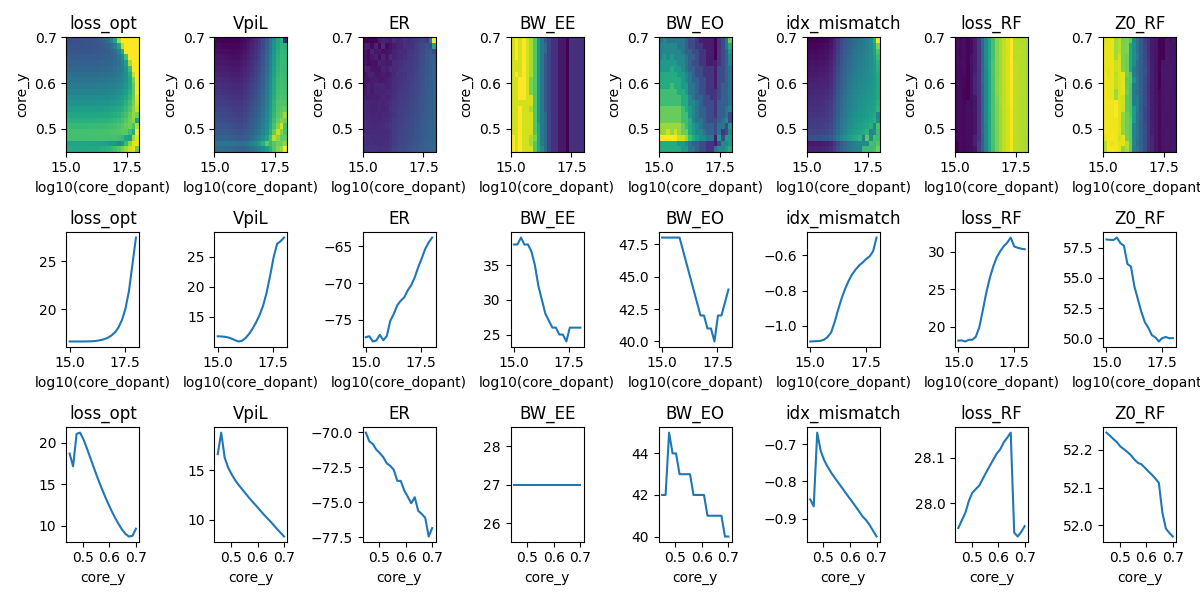

In [5]:
data = np.load("data_electronic_photonic.npy", allow_pickle=True).item()
print(data.keys())
ng_all = data.get('ng')
n_opt_all = data.get('n_opt')
loss_opt_all = data.get('loss_opt')
VpiL_all = data.get('VpiL')
ER_all = data.get('ER')
BW_EE_all = data.get('3dB_ee_bandwidth')
BW_EO_all = data.get('3dB_eo_bandwidth')
core_y_values = data.get('core_y_values')
core_dopant = data.get('core_dopant')
neff_RF_all = data.get('neff_RF')
loss_RF_all = data.get('loss_RF')
Z0_RF_all = data.get('Z0_RF')

idx_mismatch = neff_RF_all - ng_all[:,:,np.newaxis]

fig = plt.figure(figsize=(12, 6))
gs = fig.add_gridspec(3, 8)

freq_idx = 5
for i, data, label in zip(
    range(8),
        [loss_opt_all, VpiL_all, ER_all, BW_EE_all, BW_EO_all, idx_mismatch[:,:,freq_idx], loss_RF_all[:,:,freq_idx], Z0_RF_all[:,:,freq_idx]],
        ["loss_opt", "VpiL", "ER", "BW_EE", "BW_EO", "idx_mismatch", "loss_RF", "Z0_RF"]
):
    ax = fig.add_subplot(gs[0, i])

    if label in ["loss_opt"]:
        vmin = 0
        vmax = 30
    else:
        vmin = None
        vmax = None
    im = ax.imshow(data, origin='lower', extent=[np.log10(core_dopant[0]), np.log10(core_dopant[-1]), core_y_values[0], core_y_values[-1]], aspect='auto', cmap='viridis', interpolation='none', vmin=vmin, vmax=vmax)
    ax.set_title(f"{label}")
    ax.set_xlabel("log10(core_dopant)")
    ax.set_ylabel("core_y")

core_y_idx = 7
print(f"core_y_idx = {core_y_idx}, core_y = {core_y_values[core_y_idx]:.3f}")
for i, data, label in zip(
    range(8),
    [loss_opt_all, VpiL_all, ER_all, BW_EE_all, BW_EO_all, idx_mismatch[:,:,freq_idx], loss_RF_all[:,:,freq_idx], Z0_RF_all[:,:,freq_idx]],
    ["loss_opt", "VpiL", "ER", "BW_EE", "BW_EO", "idx_mismatch", "loss_RF", "Z0_RF"]
):
    ax = fig.add_subplot(gs[1, i])
    ax.plot(np.log10(core_dopant), data[core_y_idx, :])
    ax.set_title(f"{label}")
    ax.set_xlabel("log10(core_dopant)")

core_dopant_idx = 10
print(f"core_dopant_idx = {core_dopant_idx}, core_dopant = {core_dopant[core_dopant_idx]:.3e}")
for i, data, label in zip(
    range(8),
    [loss_opt_all, VpiL_all, ER_all, BW_EE_all, BW_EO_all, idx_mismatch[:,:,freq_idx], loss_RF_all[:,:,freq_idx], Z0_RF_all[:,:,freq_idx]],
    ["loss_opt", "VpiL", "ER", "BW_EE", "BW_EO", "idx_mismatch", "loss_RF", "Z0_RF"]
):
    ax = fig.add_subplot(gs[2, i])
    ax.plot(core_y_values, data[:, core_dopant_idx])
    ax.set_title(f"{label}")
    ax.set_xlabel("core_y")


fig.tight_layout()

dict_keys(['L3_dopant', 'L4_dopant', 'ng', 'n_opt', 'loss_opt', 'VpiL', 'ER', '3dB_ee_bandwidth', '3dB_eo_bandwidth', 'neff_RF', 'loss_RF', 'Z0_RF', 'phi_V'])
L4_dopant_idx = 5, L4_dopant = 46415888336127912.000
L3_dopant_idx = 5, L3_dopant = 4.642e+16


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\traitlets\traitlets.py:1385: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(


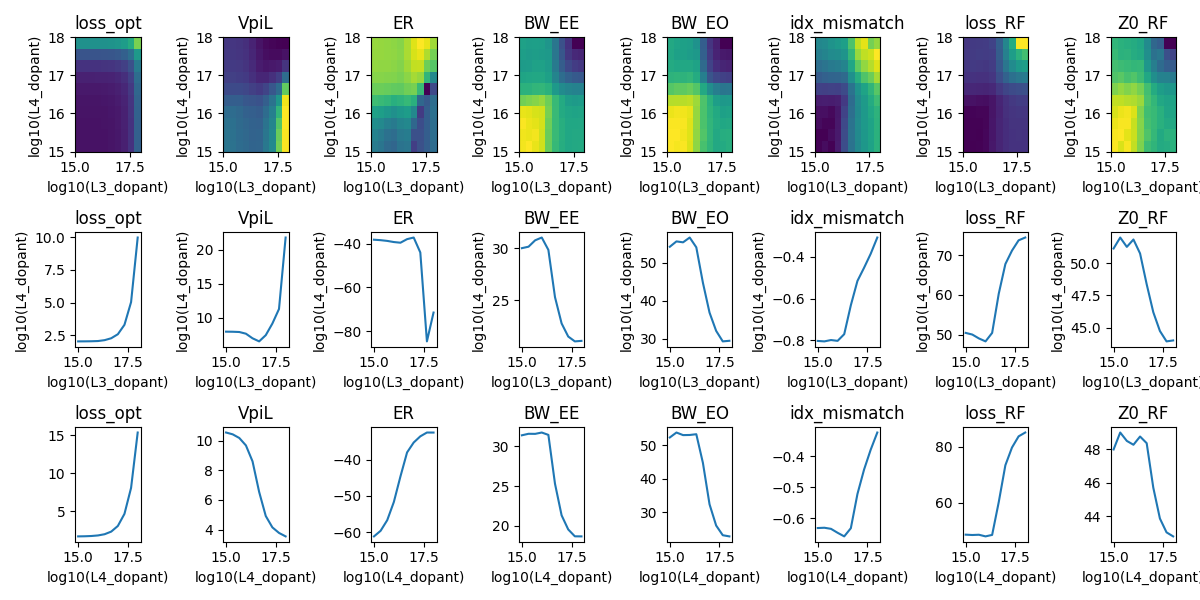

In [10]:
data = np.load("data_electronic_photonic_doping_new.npy", allow_pickle=True).item()
print(data.keys())
ng_all = data.get('ng')
n_opt_all = data.get('n_opt')
loss_opt_all = data.get('loss_opt')
VpiL_all = data.get('VpiL')
ER_all = data.get('ER')
BW_EE_all = data.get('3dB_ee_bandwidth')
BW_EO_all = data.get('3dB_eo_bandwidth')
L3_dopant = data.get('L3_dopant')
L4_dopant = -data.get('L4_dopant')
neff_RF_all = data.get('neff_RF')
loss_RF_all = data.get('loss_RF')
Z0_RF_all = data.get('Z0_RF')

idx_mismatch = neff_RF_all - ng_all[:,:,np.newaxis]

fig = plt.figure(figsize=(12, 6))
gs = fig.add_gridspec(3, 8)

freq_idx = 5
for i, data, label in zip(
    range(8),
        [loss_opt_all, VpiL_all, ER_all, BW_EE_all, BW_EO_all, idx_mismatch[:,:,freq_idx], loss_RF_all[:,:,freq_idx], Z0_RF_all[:,:,freq_idx]],
        ["loss_opt", "VpiL", "ER", "BW_EE", "BW_EO", "idx_mismatch", "loss_RF", "Z0_RF"]
):
    ax = fig.add_subplot(gs[0, i])

    if label in ["loss_opt"]:
        vmin = 0
        vmax = 30
    else:
        vmin = None
        vmax = None
    im = ax.imshow(data, origin='lower', extent=[np.log10(L3_dopant[0]), np.log10(L3_dopant[-1]), np.log10(L4_dopant[0]), np.log10(L4_dopant[-1])], aspect='auto', cmap='viridis', interpolation='none', vmin=vmin, vmax=vmax)
    ax.set_title(f"{label}")
    ax.set_xlabel("log10(L3_dopant)")
    ax.set_ylabel("log10(L4_dopant)")

L4_dopant_idx = 5
print(f"L4_dopant_idx = {L4_dopant_idx}, L4_dopant = {L4_dopant[L4_dopant_idx]:.3f}")
for i, data, label in zip(
    range(8),
    [loss_opt_all, VpiL_all, ER_all, BW_EE_all, BW_EO_all, idx_mismatch[:,:,freq_idx], loss_RF_all[:,:,freq_idx], Z0_RF_all[:,:,freq_idx]],
    ["loss_opt", "VpiL", "ER", "BW_EE", "BW_EO", "idx_mismatch", "loss_RF", "Z0_RF"]
):
    ax = fig.add_subplot(gs[1, i])
    ax.plot(np.log10(L3_dopant), data[L4_dopant_idx, :])
    ax.set_title(f"{label}")
    ax.set_xlabel("log10(L3_dopant)")
    ax.set_ylabel("log10(L4_dopant)")

L3_dopant_idx = 5
print(f"L3_dopant_idx = {L3_dopant_idx}, L3_dopant = {L3_dopant[L3_dopant_idx]:.3e}")
for i, data, label in zip(
    range(8),
    [loss_opt_all, VpiL_all, ER_all, BW_EE_all, BW_EO_all, idx_mismatch[:,:,freq_idx], loss_RF_all[:,:,freq_idx], Z0_RF_all[:,:,freq_idx]],
    ["loss_opt", "VpiL", "ER", "BW_EE", "BW_EO", "idx_mismatch", "loss_RF", "Z0_RF"]
):
    ax = fig.add_subplot(gs[2, i])
    ax.plot(np.log10(L3_dopant), data[:, L3_dopant_idx])
    ax.set_title(f"{label}")
    ax.set_xlabel("log10(L4_dopant)")
    # ax.set_ylabel(label)


fig.tight_layout()

<>:78: DeprecationWarning: invalid escape sequence '\p'
<>:78: DeprecationWarning: invalid escape sequence '\p'
C:\Users\20230622\AppData\Local\Temp\ipykernel_35788\2750840728.py:78: DeprecationWarning: invalid escape sequence '\p'
  ax2.set_title("V$_{\pi}$L [Vmm]")


dict_keys(['L3_dopant', 'L4_dopant', 'ng', 'n_opt', 'loss_opt', 'VpiL', 'ER', '3dB_ee_bandwidth', '3dB_eo_bandwidth', 'neff_RF', 'loss_RF', 'Z0_RF', 'phi_V'])


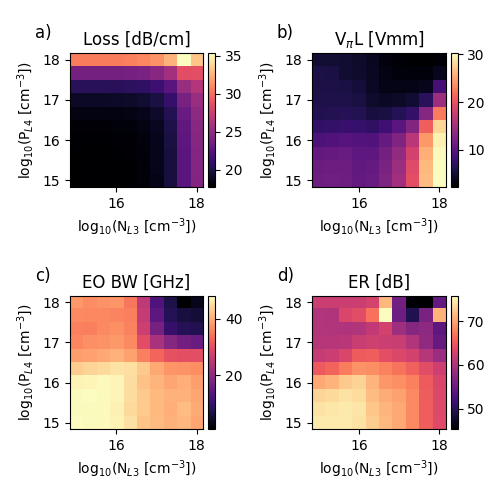

: 

In [ ]:
data = np.load("data_electronic_photonic_doping.npy", allow_pickle=True).item()
print(data.keys())
ng_all = data.get('ng')
n_opt_all = data.get('n_opt')
loss_opt_all = data.get('loss_opt')
VpiL_all = data.get('VpiL')
ER_all = data.get('ER')
BW_EE_all = data.get('3dB_ee_bandwidth')
BW_EO_all = data.get('3dB_eo_bandwidth')
L3_dopant = data.get('L3_dopant')
L4_dopant = -data.get('L4_dopant')
neff_RF_all = data.get('neff_RF')
loss_RF_all = data.get('loss_RF')
Z0_RF_all = data.get('Z0_RF')
phi_V_all = data.get('phi_V')

from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

fig = plt.figure(figsize=(5, 5))
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

dL3_dop = np.log10(L3_dopant[1]) - np.log10(L3_dopant[0])
dL4_dop = np.log10(L4_dopant[1]) - np.log10(L4_dopant[0])

cmap = 'magma'
im1 = ax1.imshow(loss_opt_all, origin='lower', extent=[np.log10(L3_dopant[0]) - dL3_dop/2, np.log10(L3_dopant[-1]) + dL3_dop/2, np.log10(L4_dopant[0]) - dL4_dop/2, np.log10(L4_dopant[-1]) + dL4_dop/2], aspect='auto', cmap=cmap, interpolation='none')
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im1, cax=cax)

im2 = ax2.imshow(VpiL_all, origin='lower', extent=[np.log10(L3_dopant[0]) - dL3_dop/2, np.log10(L3_dopant[-1]) + dL3_dop/2, np.log10(L4_dopant[0]) - dL4_dop/2, np.log10(L4_dopant[-1]) + dL4_dop/2], aspect='auto', cmap=cmap, interpolation='none')
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im2, cax=cax)

im3 = ax3.imshow(BW_EO_all, origin='lower', extent=[np.log10(L3_dopant[0]) - dL3_dop/2, np.log10(L3_dopant[-1]) + dL3_dop/2, np.log10(L4_dopant[0]) - dL4_dop/2, np.log10(L4_dopant[-1]) + dL4_dop/2], aspect='auto', cmap=cmap, interpolation='none')
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im3, cax=cax)

im4 = ax4.imshow(-ER_all, origin='lower', extent=[np.log10(L3_dopant[0]) - dL3_dop/2, np.log10(L3_dopant[-1]) + dL3_dop/2, np.log10(L4_dopant[0]) - dL4_dop/2, np.log10(L4_dopant[-1]) + dL4_dop/2], aspect='auto', cmap=cmap, interpolation='none')
divider = make_axes_locatable(ax4)
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im4, cax=cax)

VpiL_levels = [3,5,10]
loss_levels = [18,20,25]
BW_EO_levels = [20,30,40]
ER_levels = [60,70]

# color = 'white'
# CS = ax1.contour(np.log10(L3_dopant), np.log10(L4_dopant), loss_opt_all, levels=loss_levels, colors=color, linewidths=1)
# ax1.clabel(CS, inline=True, fontsize=10, fmt='%g')

# CS = ax2.contour(np.log10(L3_dopant), np.log10(L4_dopant), VpiL_all, levels=VpiL_levels, colors=color, linewidths=1)
# ax2.clabel(CS, inline=True, fontsize=10, fmt='%g')

# CS = ax3.contour(np.log10(L3_dopant), np.log10(L4_dopant), BW_EO_all, levels=BW_EO_levels, colors=color, linewidths=1)
# ax3.clabel(CS, inline=True, fontsize=10, fmt='%g')

# CS = ax4.contour(np.log10(L3_dopant), np.log10(L4_dopant), -ER_all, levels=ER_levels, colors=color, linewidths=1)
# ax4.clabel(CS, inline=True, fontsize=10, fmt='%g')

for ax, label in zip([ax1, ax2, ax3, ax4], ['a)', 'b)', 'c)', 'd)']):
    ax.set_ylim(np.log10(L4_dopant[0]) - dL4_dop/2, np.log10(L4_dopant[-1]) + dL4_dop/2)
    ax.set_xlabel("log$_{10}$(N$_{L3}$ [cm$^{-3}$])")
    ax.set_ylabel("log$_{10}$(P$_{L4}$ [cm$^{-3}$])")

    ax.set_aspect('equal')

    ax.text(-0.2,1.15, label, transform=ax.transAxes, fontsize=12, verticalalignment='center', horizontalalignment='center')
ax1.set_title("Loss [dB/cm]")
ax2.set_title("V$_{\pi}$L [Vmm]")
ax3.set_title("EO BW [GHz]")
ax4.set_title("ER [dB]")

fig.tight_layout()
fig.savefig(r'..\Images\electronic_photonic_codesign.png', dpi=300)

[5.80405804 5.79105791 5.72705727 5.29205292 4.10804108 3.5400354
 3.33203332 3.48603486 3.6800368  8.48508485]
[5.80405804 5.79105791 5.72705727 5.29205292 4.10804108 3.5400354
 3.33203332 3.48603486 3.6800368  8.48508485]
[5.80405804 5.79105791 5.72705727 5.29205292 4.10804108 3.5400354
 3.33203332 3.48603486 3.6800368  8.48508485]


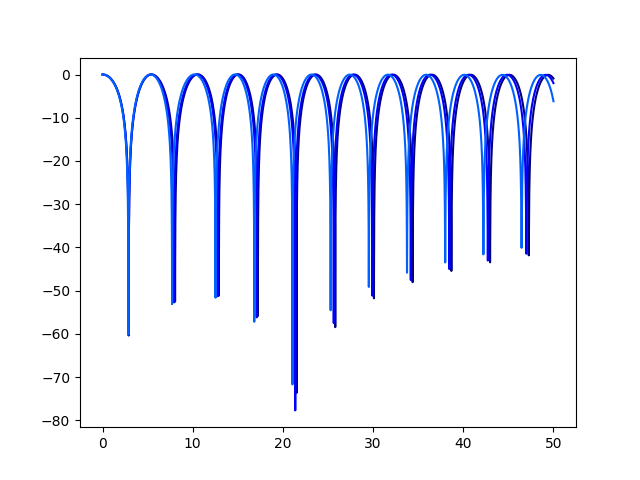

In [114]:
plt.figure()

colors = plt.cm.jet(np.linspace(0, 1, 10))
for k in range(10):
    i,j = 7,k
    phi = phi_V_all[i,j]
    print(VpiL_all[i])

    V = np.linspace(0,50,100_000)
    new_V = np.linspace(0,50,100_000)
    new_phi = interp1d(V, phi)(new_V)
    MZM_output = 1/2 * (1 + np.exp(1j*new_phi))
    MZM_Iout = np.abs(MZM_output)**2


    plt.plot(new_V, 10*np.log10(MZM_Iout), color=colors[k], label=f"L3 dop = {L3_dopant[k]:.2e}")

    if k == 2:
        # plt.plot(new_V, 10*np.log10(MZM_Iout), color=colors[k], label=f"L3 dop = {L3_dopant[k]:.2e}")
        break

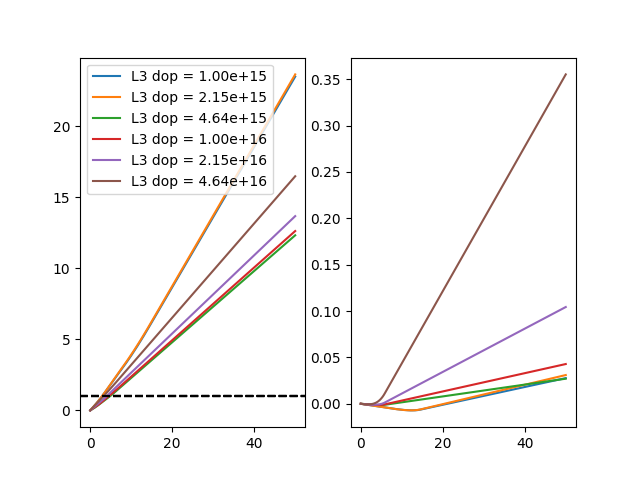

In [127]:
fig = plt.figure()
gs = fig.add_gridspec(1, 2)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

for k in range(10):
    i,j = 8,k
    phi = phi_V_all[i,j]

    V = np.linspace(0,50,100_000)
    new_V = np.linspace(0,50,100_000)
    new_phi = interp1d(V, phi)(new_V)
    MZM_output = 1/2 * (1 + np.exp(1j*new_phi))
    MZM_Iout = np.abs(MZM_output)**2


    ax1.plot(new_V, new_phi.real/np.pi, label=f"L3 dop = {L3_dopant[j]:.2e}")
    ax1.axhline(1, color='k', linestyle='--')
    ax2.plot(new_V, new_phi.imag)

    if k == 5:
        break
    

ax1.legend()